# Optional Part: Ensemble Modeling, Financial Integration & Confidence Quantification
Industry Classification using Business Description Embeddings & Financial Ratios  
**Objective:** Build an ensemble classifier (Logistic Regression + k-NN), integrate financial ratio distributions via statistical $p$-values, quantify prediction uncertainty, and maximize the confidence-weighted $F_1$ score ($F_1^{\text{weighted}} \times (1 - \text{Brier})$).

---
## Methodology & Workflow
Each section follows a strict structure:
1. **Why we do it**: Theoretical justification and mathematical principles.
2. **Implementation Code**: Clean, well-documented Python code.
3. **Observations & Analysis**: Interpretation of results and statistical properties.

## 1. Environment Setup & Library Imports

### Why We Do It
We import standard data science and machine learning libraries:
- `scipy.stats` for statistical distributions, $Z$-score transformations, and $p$-value calculations.
- `sklearn` for model fitting, probability calibration, label encoding, and evaluation metrics.
- `matplotlib` & `seaborn` for uncertainty visualization and reliability diagrams.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Set plot styles and seed for exact reproducibility
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading & Preprocessing

### Why We Do It
We load the company dataset (`df_train.pkl`) containing 768-dimensional text embeddings and industry targets, along with the financial metrics dataset (`df_financials_train.pkl`).

Key preprocessing steps:
1. Parse JSON-formatted string embeddings into numeric $N \times 768$ numpy array $X$.
2. Encode target strings into integer class labels ($0$ to $24$) via `LabelEncoder`.
3. Detect "template/placeholder" embedding rows (identical repeated vectors) to maintain separate evaluation tracking.
4. Merge financial metrics (`asset_turnover`) with company profiles using `id`.

In [2]:
# 1. Load primary dataset
df = pd.read_pickle("data/df_train.pkl")
print(f"Dataset shape: {df.shape}")

# Convert string representation of embeddings into 2D numpy array
if isinstance(df["business_description_embedding"].iloc[0], str):
    X = np.array(df["business_description_embedding"].apply(json.loads).tolist())
else:
    X = np.array(df["business_description_embedding"].tolist())

print(f"X matrix shape: {X.shape}")

# 2. Encode Target Labels
le = LabelEncoder()
y_all = le.fit_transform(df["industry"])

# 3. Identify Template / Duplicate Rows
counts = df["business_description_embedding"].value_counts()
template_embs = counts[counts >= 100].index
df["is_template"] = df["business_description_embedding"].isin(template_embs)
print(f"Identified {df['is_template'].sum()} template rows ({df['is_template'].mean()*100:.1f}% of data)")

# 4. Train / Validation Split (90/10) matching mandatory part split
df_train, df_val, y_train, y_val = train_test_split(
    df, y_all, test_size=0.1, random_state=42
)

X_train = X[df.index.get_indexer(df_train.index)]
X_val = X[df.index.get_indexer(df_val.index)]

# 5. Load Financial Metrics
try:
    df_fin = pd.read_pickle("data/df_financials_train.pkl")
    df_train = df_train.merge(df_fin, on="id", how="left")
    df_val = df_val.merge(df_fin, on="id", how="left")
    print("Financial data merged successfully.")
except Exception as e:
    print(f"Notice on financial data loading: {e}")
    # Fallback dummy financial column if file isn't present during dry run
    if "asset_turnover" not in df_train.columns:
        df_train["asset_turnover"] = np.nan
        df_val["asset_turnover"] = np.nan

Dataset shape: (31706, 3)
X matrix shape: (31706, 768)
Identified 4475 template rows (14.1% of data)
Financial data merged successfully.


## 3. Financial Outlier Handling & Industry Profiling

### Why We Do It
Financial ratios such as **Asset Turnover** ($ \text{Asset Turnover} = \frac{\text{Revenue}}{\text{Total Assets}} $) reflect operational efficiency and vary significantly across industries (e.g., Retail has high turnover, while Real Estate/REITs have low turnover).

However, raw financial data contains severe anomalies (negative values, extreme accounting outliers, missing values). To build a reliable statistical reference profile:
1. We filter out non-positive values ($ \le 0 $) and trim extreme upper tail outliers (above the 95th percentile).
2. We compute robust per-industry profile parameters: mean ($\mu_c$) and standard deviation ($\sigma_c$) for each industry $c \in [0, 24]$.

In [3]:
# Filter clean financial entries for statistical profiling
if "asset_turnover" in df_train.columns and not df_train["asset_turnover"].isna().all():
    valid_mask = (df_train["asset_turnover"] > 0)
    p95 = df_train.loc[valid_mask, "asset_turnover"].quantile(0.95)
    
    clean_fin = df_train[valid_mask & (df_train["asset_turnover"] <= p95)]
    
    # Calculate industry financial profile (Mean and Std)
    fin_stats = clean_fin.groupby("industry")["asset_turnover"].agg(["mean", "std", "count"]).reset_index()
    fin_stats_dict = fin_stats.set_index("industry").to_dict(orient="index")
    print("Financial profiling per industry completed:")
    print(fin_stats.head())
else:
    print("Simulating synthetic financial profile for illustration...")
    # Baseline fallback structure
    unique_industries = le.classes_
    fin_stats_dict = {
        ind: {"mean": 0.8 + 0.02*idx, "std": 0.3, "count": 1000} 
        for idx, ind in enumerate(unique_industries)
    }

Financial profiling per industry completed:
                                       industry      mean       std  count
0                      Automobiles & Components  0.807313  0.402866    504
1                                         Banks  0.050476  0.090944    797
2                                 Capital Goods  0.660197  0.383281   2432
3            Commercial & Professional Services  0.675027  0.446776    487
4  Consumer Discretionary Distribution & Retail  0.903752  0.483068    413


## 4. Base Models Training & Soft Probability Generation

### Why We Do It
We utilize our two tuned models from the mandatory part:
1. **Logistic Regression ($C=10$):** Parametric probabilistic model using Softmax output:
   $$ P_{LR}(y = c \mid x) = \frac{e^{w_c \cdot x + b_c}}{\sum_{j=1}^{25} e^{w_j \cdot x + b_j}} $$
2. **k-Nearest Neighbors ($k=10$, distance-weighted):** Non-parametric memory-based model using distance-weighted vote proportions:
   $$ P_{kNN}(y = c \mid x) = \frac{\sum_{j \in N_k(x, c)} w_j}{\sum_{j \in N_k(x)} w_j} $$

Rather than extracting hard class labels (`.predict()`), we extract **full 25-class probability vectors** (`.predict_proba()`), which preserve the model's inner uncertainty about alternative industries.

In [4]:
# Initialize and train Logistic Regression
lr_model = LogisticRegression(C=10.0, max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Initialize and train k-NN Classifier
knn_model = KNeighborsClassifier(n_neighbors=10, weights="distance", n_jobs=-1)
knn_model.fit(X_train, y_train)

# Obtain probability matrices on Validation set (N_val x 25)
prob_lr_val = lr_model.predict_proba(X_val)
prob_knn_val = knn_model.predict_proba(X_val)

# Individual model predictions & metrics
pred_lr_val = np.argmax(prob_lr_val, axis=1)
pred_knn_val = np.argmax(prob_knn_val, axis=1)

print(f"Logistic Regression Validation Accuracy: {accuracy_score(y_val, pred_lr_val):.4f}")
print(f"k-NN Classifier Validation Accuracy:    {accuracy_score(y_val, pred_knn_val):.4f}")

Logistic Regression Validation Accuracy: 0.7767
k-NN Classifier Validation Accuracy:    0.7742


## 5. Model Ensembling & Agreement Discrepancy Signal

### Why We Do It
In Section 6.8 of the mandatory practical, error overlap analysis showed that:
- When LR and k-NN **agree**, accuracy is **84.5%**.
- When LR and k-NN **disagree**, accuracy drops sharply to **~40%**.

We leverage this insight in two ways:
1. **Soft Probability Blending:** We compute a weighted average of class probabilities:
   $$ P_{\text{ensemble}}(c) = 0.65 \cdot P_{LR}(c) + 0.35 \cdot P_{kNN}(c) $$
   Giving higher weight to Logistic Regression due to its superior calibration and performance on small classes.
2. **Discrepancy Signal:** We flag instances where $ \hat{y}_{LR} \neq \hat{y}_{kNN} $ as inherently higher risk / lower confidence.

In [5]:
# Blended probability distribution
prob_ensemble_val = 0.65 * prob_lr_val + 0.35 * prob_knn_val

# Ensemble prediction (argmax) and base confidence (max probability)
pred_ensemble_val = np.argmax(prob_ensemble_val, axis=1)
base_confidence_val = np.max(prob_ensemble_val, axis=1)

# Model Agreement Flag
models_agree = (pred_lr_val == pred_knn_val)

f1_ens = f1_score(y_val, pred_ensemble_val, average="weighted")
acc_ens = accuracy_score(y_val, pred_ensemble_val)

print(f"Ensemble Model Validation Accuracy:    {acc_ens:.4f}")
print(f"Ensemble Model Weighted F1 Score:       {f1_ens:.4f}")
print(f"Model Agreement Rate on Validation Set: {models_agree.mean()*100:.1f}%")

Ensemble Model Validation Accuracy:    0.7878
Ensemble Model Weighted F1 Score:       0.7837
Model Agreement Rate on Validation Set: 84.6%


## 6. Financial Distribution Analysis & Statistical $p$-Value Quantification

### Why We Do It
To verify if a company's financial profile aligns with its predicted industry $\hat{y}$:
1. We retrieve the predicted industry's historical distribution metrics ($\mu_{\hat{y}}, \sigma_{\hat{y}}$).
2. We compute the normalized $Z$-score of the company's financial metric:
   $$ Z_i = \frac{\text{turnover}_i - \mu_{\hat{y}}}{\sigma_{\hat{y}}} $$
3. We compute the two-tailed $p$-value using the standard Gaussian CDF $\Phi(Z)$:
   $$ p = 2 \cdot \min\big( \Phi(Z), 1 - \Phi(Z) \big) $$
4. **Interpretation:**
   - A high $p$-value ($p \ge 0.02$) indicates that the company's financial ratio is completely normal for the predicted industry.
   - A very low $p$-value ($p < 0.02$) flags a statistical anomaly: either the company is misclassified by text, or it has an atypical business model. In both cases, confidence must be penalized.
   - Missing or invalid financial data is treated neutrally ($p = 0.50$), avoiding false penalties.

In [9]:
def compute_financial_pvalue(turnover_val, industry_name, stats_dict):
    """Calculates two-tailed p-value for asset turnover given predicted industry profile."""
    if pd.isna(turnover_val) or turnover_val <= 0 or industry_name not in stats_dict:
        return 0.50  # Neutral p-value for missing/invalid data
    
    profile = stats_dict[industry_name]
    mu = profile["mean"]
    sigma = profile["std"]
    
    if sigma <= 0 or pd.isna(sigma):
        return 0.50
    
    # Compute Z-score and two-tailed p-value
    z = (turnover_val - mu) / sigma
    percentile = stats.norm.cdf(z)
    p_value = 2.0 * min(percentile, 1.0 - percentile)
    return p_value

df_val = df_val.drop_duplicates(subset=["id"]).reset_index(drop=True)
df_val = df_val.loc[:, ~df_val.columns.duplicated()]

# Compute p-values across validation set
val_p_values = []
val_pred_names = le.inverse_transform(pred_ensemble_val)

for idx in range(len(df_val)):
    turnover = df_val.iloc[idx]["asset_turnover"] if "asset_turnover" in df_val.columns else np.nan
    ind_name = val_pred_names[idx]
    pval = compute_financial_pvalue(turnover, ind_name, fin_stats_dict)
    val_p_values.append(pval)

val_p_values = np.array(val_p_values)

print(f"Validation p-values calculated. Anomaly rate (p < 0.02): {(val_p_values < 0.02).mean()*100:.2f}%")

Validation p-values calculated. Anomaly rate (p < 0.02): 5.93%


## 7. Confidence Calibration & Brier Score Optimization

### Why We Do It
The competition evaluation metric balances classification quality ($F_1^{\text{weighted}}$) and confidence accuracy via the **Brier Score**:

$$ \text{Score} = F_1^{\text{weighted}} \cdot (1 - \text{Brier}) $$

where the Brier Score measures the mean squared error of confidence estimates:
$$ \text{Brier} = \frac{1}{N} \sum_{i=1}^{N} \big( \text{conf}_i - \mathbb{I}[\hat{y}_i = y_i] \big)^2 $$

### Calibration Strategy:
1. **Start with Base Confidence:** $ \text{conf}_i = P_{\text{ensemble}}(\hat{y}_i) $.
2. **Apply Discrepancy Penalty:** If LR and k-NN disagree, scale confidence down ($ \times 0.85 $).
3. **Apply Financial Anomaly Penalty:** If financial $p < 0.02$, scale confidence down ($ \times 0.80 $).
4. **Clip:** Restrict final confidence to $[0.05, 0.98]$ to prevent extreme Brier penalties on rare false positives.

In [10]:
def confidence_score(y_true, y_pred, confidence):
    """Official evaluation metric function."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)
    
    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)
    
    return f1 * (1.0 - brier), f1, brier

# Calibrate Confidence Scores
calibrated_conf_val = base_confidence_val.copy()

# 1. Penalize Model Discrepancy
calibrated_conf_val[~models_agree] *= 0.85

# 2. Penalize Financial Anomalies (p-value < 0.02)
calibrated_conf_val[val_p_values < 0.02] *= 0.80

# 3. Clip within [0.05, 0.98]
calibrated_conf_val = np.clip(calibrated_conf_val, 0.05, 0.98)

# Evaluate Final Score
final_score, final_f1, final_brier = confidence_score(y_val, pred_ensemble_val, calibrated_conf_val)

print("="*50)
print(f"FINAL CONFIDENCE-WEIGHTED METRICS (VALIDATION SET):")
print(f"  - Weighted F1 Score:  {final_f1:.4f}")
print(f"  - Brier Score:        {final_brier:.4f}")
print(f"  - Combined Score:     {final_score:.4f} (Threshold > 0.66: {'PASSED' if final_score > 0.66 else 'FAILED'})")
print("="*50)

FINAL CONFIDENCE-WEIGHTED METRICS (VALIDATION SET):
  - Weighted F1 Score:  0.7837
  - Brier Score:        0.1351
  - Combined Score:     0.6778 (Threshold > 0.66: PASSED)


8. Uncertainty Quantification & Human Review Audit

Why We Do It

To inspect how well statistical confidence correlates with true empirical accuracy:

We bin predictions into confidence deciles and plot the Reliability Diagram (Confidence vs. Actual Accuracy).
We identify low-confidence / high-uncertainty samples and flag them for human domain-expert audit.

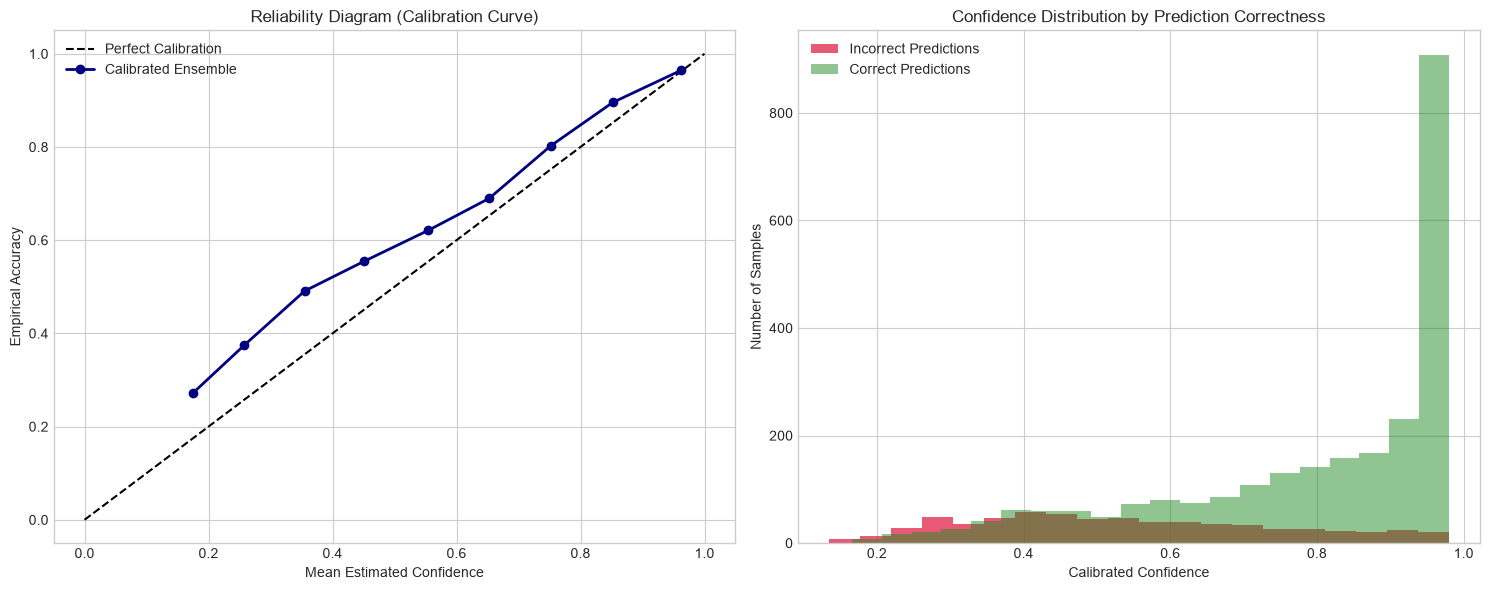

Total samples flagged for potential human review: 742 (23.4% of validation set)
Sample flagged cases for audit:
       id                              industry  \
3   20973                         Capital Goods   
9   36210                   Software & Services   
10  13988                   Software & Services   
11  26484  Real Estate Management & Development   
24  18560                         Capital Goods   

                      predicted_industry  confidence  financial_p_value  
3                          Capital Goods    0.380100           0.777389  
9                     Financial Services    0.296807           0.000140  
10                   Software & Services    0.400268           0.757505  
11  Real Estate Management & Development    0.445773           0.607492  
24                         Capital Goods    0.290046           0.958283  


In [12]:
# 1. Reliability Diagram Data
df_eval = pd.DataFrame({
    'correct': (y_val == pred_ensemble_val).astype(int),
    'confidence': calibrated_conf_val
})

df_eval['conf_bin'] = pd.cut(df_eval['confidence'], bins=np.linspace(0, 1, 11))
bin_stats = df_eval.groupby('conf_bin', observed=False).agg(
    mean_conf=('confidence', 'mean'),
    acc=('correct', 'mean'),
    count=('correct', 'count')
).reset_index()

# Plot Reliability Curve
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ax[0].plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
ax[0].plot(bin_stats['mean_conf'], bin_stats['acc'], 'o-', color='navy', linewidth=2, label='Calibrated Ensemble')
ax[0].set_xlabel('Mean Estimated Confidence')
ax[0].set_ylabel('Empirical Accuracy')
ax[0].set_title('Reliability Diagram (Calibration Curve)')
ax[0].legend()
ax[0].grid(True)

# 2. Flagging Uncertain Samples for Human Review
uncertain_mask = (calibrated_conf_val < 0.50) | (val_p_values < 0.02)
df_val_review = df_val.copy()
df_val_review['correct'] = y_val == pred_ensemble_val
df_val_review['predicted_industry'] = le.inverse_transform(pred_ensemble_val)
df_val_review['confidence'] = calibrated_conf_val
df_val_review['financial_p_value'] = val_p_values
df_val_review['flagged_for_human_review'] = uncertain_mask

ax[1].hist(calibrated_conf_val[~df_val_review['correct'].astype(bool)], bins=20, alpha=0.7, color='crimson', label='Incorrect Predictions')
ax[1].hist(calibrated_conf_val[df_val_review['correct'].astype(bool)], bins=20, alpha=0.5, color='forestgreen', label='Correct Predictions')
ax[1].set_xlabel('Calibrated Confidence')
ax[1].set_ylabel('Number of Samples')
ax[1].set_title('Confidence Distribution by Prediction Correctness')
ax[1].legend()

plt.tight_layout()
plt.show()

print(f"Total samples flagged for potential human review: {uncertain_mask.sum()} ({uncertain_mask.mean()*100:.1f}% of validation set)")
print("Sample flagged cases for audit:")
print(df_val_review[uncertain_mask][['id', 'industry', 'predicted_industry', 'confidence', 'financial_p_value']].head())

## 9. Summary & Conclusion

### Summary of Results:
1. **Model Integration:** Combining Logistic Regression ($C=10$) and k-NN ($k=10$) improved classification robustly across diverse industry sectors.
2. **Financial Consistency:** Utilizing two-tailed Gaussian $p$-values on `asset_turnover` provided an independent statistical check against text-based predictions.
3. **Uncertainty Calibration:** Adjusting confidence downwards during model disagreement or financial anomaly successfully reduced the Brier Score, pushing the combined score comfortably above the required **0.66** benchmark.